In [145]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv('/content/drive/MyDrive/DATA/Dataset_Transaksi_Toko.csv')
data.head()


,id_pesanan,id_pelanggan,tanggal_pesan,tanggal_kirim,wilayah,kategori_produk,kanal_penjualan,metode_bayar,status_pesanan,prioritas,...,jumlah_retur,nilai_retur,rating,frekuensi_90hari,total_belanja_90hari,rata_keranjang_90hari,usia_salin,mata_uang,sumber_sistem,terakhir_diperbarui
0,ORD000324,C0019,2026-01-08,2026-01-13,Lamongan,Rumah Tangga,Aplikasi,Kartu Kredit,Selesai,Tinggi,...,0,0,4,20,10000000,500000.0,69,IDR,POS,2026-02-17T08:00:00
1,ORD000573,C0041,2026-05-07,12/05/2026,Gresik,Kesehatan,Outlet,COD,Selesai,Sedang,...,0,0,3,6,5700000,950000.0,60,IDR,POS,2026-06-16T08:00:00
2,ORD000387,C0113,46136,29/04/2026,Sidoarjo,Fashion,NaN,Cash On Delivery,Selesai,Rendah,...,0,0,1,22,990000,45000.0,32,IDR,WEB,2026-06-03T08:00:00
3,ORD000431,C0015,2026-02-02,2026-02-07,Tuban,Elektronik,b2b,Transfer Bank,Selesai,Sedang,...,0,0,4,23,11500000,500000.0,NaN,IDR,WEB,2026-03-14T08:00:00
4,ORD000107,C0107,46164,46168,Surabaya,Elektronik,Web,COD,Selesai,Sedang,...,0,0,2,21,19950000,950000.0,25 tahun,IDR,WEB,2026-07-01T08:00:00


**KOLOM NUMERIK**

Pada dataset ini beberapa angka masih tersimpan sebagai teks, misalnya 25 tahun dan Rp 15.000,00

In [181]:
# Mengubah usia menjadi numerik
data["usia_pelanggan"] = data["usia_pelanggan"].astype(str).str.replace(" tahun", "", regex=False)
data["usia_pelanggan"] = pd.to_numeric(data["usia_pelanggan"], errors="coerce")

In [182]:
# DETEKSI IMPOSSIBLE VALUE
print("Usia tidak wajar (<= 0):")
display(data[data["usia_pelanggan"] <= 0][["usia_pelanggan"]])
print("Usia tidak wajar (>= 120):")
display(data[data["usia_pelanggan"] >= 120][["usia_pelanggan"]])

Usia tidak wajar (<= 0):


,usia_pelanggan


Usia tidak wajar (>= 120):


,usia_pelanggan


In [183]:
# Nilai usia yang tidak wajar dihapus
data.loc[(data["usia_pelanggan"] <= 0) | (data["usia_pelanggan"] >= 120),
         "usia_pelanggan"] = np.nan

In [184]:
# KONVERSI DATA KE NUMERIK

def baca_angka(nilai):
    if pd.isna(nilai):
        return np.nan

    teks = (
        str(nilai)
        .strip()
        .replace("Rp", "")
        .replace(" ", "")
        .replace("\u00a0", "")
    )

    # Mengubah format angka Indonesia menjadi format numerik
    if "," in teks:
        teks = teks.replace(".", "").replace(",", ".")

    return pd.to_numeric(teks, errors="coerce")


kolom_angka = [
    "pendapatan_bulanan",
    "harga_satuan",
    "ongkir",
    "berat_kiriman",
    "durasi_proses",
    "rating",
    "frekuensi_90hari",
    "total_belanja_90hari",
    "usia_salin"
]

for kolom in kolom_angka:
    data[kolom] = data[kolom].map(baca_angka)


# Mengubah diskon persen menjadi desimal
diskon_asli = (
    data["diskon"]
    .astype("string")
    .str.strip()
)

mask_persen = diskon_asli.str.contains("%", na=False)

diskon_bersih = (
    diskon_asli
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)

data["diskon"] = pd.to_numeric(
    diskon_bersih,
    errors="coerce"
)

data.loc[mask_persen, "diskon"] = (
    data.loc[mask_persen, "diskon"] / 100
)

# Diskon harus berada pada rentang 0 sampai 1
data.loc[
    (data["diskon"] < 0) | (data["diskon"] > 1),
    "diskon"
] = np.nan


# Mengubah jumlah barang yang ditulis dengan kata
data["jumlah_barang"] = (
    data["jumlah_barang"]
    .astype("string")
    .str.lower()
    .str.strip()
    .replace({
        "satu": "1",
        "dua": "2",
        "tiga": "3",
        "empat": "4",
        "lima": "5"
    })
)

data["jumlah_barang"] = pd.to_numeric(
    data["jumlah_barang"],
    errors="coerce"
)

print("Statistik diskon setelah konversi:")
display(data[["diskon"]].describe())

print("Data setelah konversi numerik:")
display(data.head())

Statistik diskon setelah konversi:


,diskon
count,645.0
mean,0.106279
std,0.086262
min,0.0
25%,0.0
50%,0.1
75%,0.2
max,0.25


Data setelah konversi numerik:


,id_pesanan,id_pelanggan,tanggal_pesan,tanggal_kirim,wilayah,kategori_produk,kanal_penjualan,metode_bayar,status_pesanan,prioritas,...,jumlah_retur,nilai_retur,rating,frekuensi_90hari,total_belanja_90hari,rata_keranjang_90hari,usia_salin,mata_uang,sumber_sistem,terakhir_diperbarui
0,ORD000324,C0019,2026-01-08,2026-01-13,Lamongan,Rumah Tangga,Aplikasi,Kartu Kredit,Selesai,Tinggi,...,0,0,4.0,20.0,10000000.0,500000.0,69.0,IDR,POS,2026-02-17T08:00:00
1,ORD000573,C0041,2026-05-07,12/05/2026,Gresik,Kesehatan,Outlet,COD,Selesai,Sedang,...,0,0,3.0,6.0,5700000.0,950000.0,60.0,IDR,POS,2026-06-16T08:00:00
2,ORD000387,C0113,46136,29/04/2026,Sidoarjo,Fashion,Aplikasi,Cash On Delivery,Selesai,Rendah,...,0,0,1.0,22.0,990000.0,45000.0,32.0,IDR,WEB,2026-06-03T08:00:00
3,ORD000431,C0015,2026-02-02,2026-02-07,Tuban,Elektronik,b2b,Transfer Bank,Selesai,Sedang,...,0,0,4.0,23.0,11500000.0,500000.0,42.0,IDR,WEB,2026-03-14T08:00:00
4,ORD000107,C0107,46164,46168,Surabaya,Elektronik,Web,COD,Selesai,Sedang,...,0,0,2.0,21.0,19950000.0,950000.0,25.0,IDR,WEB,2026-07-01T08:00:00


In [185]:
# MENGUBAH TOTAL BAYAR MENJADI NUMERIK

data["total_bayar"] = (
    data["total_bayar"].map(baca_angka)
)

print("Tipe data total bayar:")
print(data["total_bayar"].dtype)

print("Contoh total bayar setelah konversi:")
display(data[["total_bayar"]].head(10))

Tipe data total bayar:
float64
Contoh total bayar setelah konversi:


,total_bayar
0,1870000.0
1,95000.0
2,67500.0
3,2390000.0
4,580000.0
5,29600.0
6,181250.0
7,695000.0
8,242625.0
9,7312500.0


In [151]:
data.head()

,id_pesanan,id_pelanggan,tanggal_pesan,tanggal_kirim,wilayah,kategori_produk,kanal_penjualan,metode_bayar,status_pesanan,prioritas,...,jumlah_retur,nilai_retur,rating,frekuensi_90hari,total_belanja_90hari,rata_keranjang_90hari,usia_salin,mata_uang,sumber_sistem,terakhir_diperbarui
0,ORD000324,C0019,2026-01-08,2026-01-13,Lamongan,Rumah Tangga,Aplikasi,Kartu Kredit,Selesai,Tinggi,...,0,0,4.0,20.0,10000000.0,500000.0,69.0,IDR,POS,2026-02-17T08:00:00
1,ORD000573,C0041,2026-05-07,12/05/2026,Gresik,Kesehatan,Outlet,COD,Selesai,Sedang,...,0,0,3.0,6.0,5700000.0,950000.0,60.0,IDR,POS,2026-06-16T08:00:00
2,ORD000387,C0113,46136,29/04/2026,Sidoarjo,Fashion,NaN,Cash On Delivery,Selesai,Rendah,...,0,0,1.0,22.0,990000.0,45000.0,32.0,IDR,WEB,2026-06-03T08:00:00
3,ORD000431,C0015,2026-02-02,2026-02-07,Tuban,Elektronik,b2b,Transfer Bank,Selesai,Sedang,...,0,0,4.0,23.0,11500000.0,500000.0,NaN,IDR,WEB,2026-03-14T08:00:00
4,ORD000107,C0107,46164,46168,Surabaya,Elektronik,Web,COD,Selesai,Sedang,...,0,0,2.0,21.0,19950000.0,950000.0,25.0,IDR,WEB,2026-07-01T08:00:00


In [186]:
# MENYAMAKAN SATUAN BERAT

berat_sebelum = data[
    ["berat_kiriman", "satuan_berat"]
].copy()

satuan = (
    data["satuan_berat"]
    .astype("string")
    .str.strip()
    .str.lower()
)

faktor_berat = satuan.map({
    "kg": 1,
    "g": 0.001,
    "gram": 0.001,
    "pound": 0.453592,
    "stone": 6.35029
})

# Memeriksa satuan yang belum dikenali
satuan_tidak_dikenali = (
    satuan.notna() & faktor_berat.isna()
)

print("Satuan yang belum dikenali:")
display(
    data.loc[
        satuan_tidak_dikenali,
        ["berat_kiriman", "satuan_berat"]
    ]
)

# Mengubah berat menjadi kilogram
data["berat_kiriman"] = (
    data["berat_kiriman"] * faktor_berat
)

# Berat nol atau negatif dianggap tidak valid
data.loc[
    data["berat_kiriman"] <= 0,
    "berat_kiriman"
] = np.nan

data["satuan_berat"] = "kg"

perbandingan_berat = berat_sebelum.rename(
    columns={
        "berat_kiriman": "Berat_Sebelum",
        "satuan_berat": "Satuan_Sebelum"
    }
)

perbandingan_berat["Berat_Kg"] = data["berat_kiriman"]

print("Perbandingan berat sebelum dan sesudah konversi:")
display(perbandingan_berat.head(10))

Satuan yang belum dikenali:


,berat_kiriman,satuan_berat


Perbandingan berat sebelum dan sesudah konversi:


,Berat_Sebelum,Satuan_Sebelum,Berat_Kg
0,2969.000,g,2.969
1,3.987,kg,3.987
2,3.904,kg,3.904
3,5.304,kg,5.304
4,4471.000,G,4.471
5,0.168,kg,0.168
6,2.306,kg,2.306
7,4.127,kg,4.127
8,2.478,kg,2.478
9,149.203,kg,149.203


In [187]:
# DETEKSI MISSING VALUE

# Mengubah spasi kosong menjadi NaN
data = data.replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# Mengubah penanda data kosong menjadi NaN
data = data.replace([
    "?",
    "-",
    "Tidak diisi",
    "tidak diisi",
    "Tidak diketahui",
    "tidak diketahui"
], np.nan)

missing = pd.DataFrame({
    "Jumlah Missing": data.isnull().sum(),
    "Persentase Missing (%)": (
        data.isnull().mean() * 100
    ).round(2)
})

print("Jumlah missing value setiap kolom:")
display(
    missing[
        missing["Jumlah Missing"] > 0
    ]
)

# Statistik deskriptif sebelum pengisian missing value
print("Statistik deskriptif numerik:")
display(data.describe())

print("Statistik deskriptif kategorik:")
display(data.describe(include="object"))

Jumlah missing value setiap kolom:


,Jumlah Missing,Persentase Missing (%)
tanggal_kirim,121,18.76
berat_kiriman,4,0.62


Statistik deskriptif numerik:


,usia_pelanggan,pendapatan_bulanan,jumlah_barang,harga_satuan,diskon,ongkir,total_bayar,berat_kiriman,durasi_proses,jumlah_retur,nilai_retur,rating,frekuensi_90hari,total_belanja_90hari,rata_keranjang_90hari,usia_salin
count,645.000000,6.450000e+02,645.0,6.450000e+02,645.0,645.000000,6.450000e+02,641.000000,645.000000,645.000000,6.450000e+02,645.000000,645.000000,6.450000e+02,645.000000,645.000000
mean,43.217829,6.199067e+06,3.732093,1.337489e+07,0.106279,20488.372093,1.279179e+06,5.968332,13.545989,0.248062,7.681969e+04,3.643411,11.986047,3.760287e+06,320689.922481,58.893798
std,14.374410,7.049198e+06,12.108788,2.957243e+08,0.086262,16180.688915,3.968595e+06,22.966114,26.453419,1.135474,5.468278e+05,1.215828,7.034396,5.025372e+06,322945.652372,392.337239
min,17.500000,-5.000000e+05,-3.0,1.200000e+01,0.0,-25000.000000,0.000000e+00,0.102000,-12.000000,0.000000,0.000000e+00,-1.000000,0.000000,0.000000e+00,0.000000,-10.000000
25%,31.000000,3.900000e+06,1.0,4.500000e+04,0.0,10000.000000,9.650000e+04,1.571000,1.811000,0.000000,0.000000e+00,3.000000,6.000000,8.500000e+05,85000.000000,31.000000
50%,42.000000,5.100000e+06,2.0,1.200000e+05,0.1,15000.000000,2.426250e+05,3.189000,3.223000,0.000000,0.000000e+00,4.000000,12.000000,1.800000e+06,150000.000000,42.000000
75%,54.000000,6.800000e+06,3.0,2.500000e+05,0.2,35000.000000,7.475000e+05,5.315000,4.620000,0.000000,0.000000e+00,4.000000,18.000000,4.250000e+06,500000.000000,54.000000
max,72.000000,1.250000e+08,195.0,7.500000e+09,0.25,50000.000000,6.005000e+07,482.515000,119.496000,20.000000,7.500000e+06,9.000000,24.000000,2.280000e+07,950000.000000,9999.000000


Statistik deskriptif kategorik:


,id_pesanan,id_pelanggan,tanggal_pesan,tanggal_kirim,wilayah,kategori_produk,kanal_penjualan,metode_bayar,status_pesanan,prioritas,status_member,satuan_harga,satuan_berat,satuan_durasi,mata_uang,sumber_sistem,terakhir_diperbarui
count,645,645,645,524,645,645,645,645,645,645,645,645,645,645,645,645,645
unique,615,214,259,246,5,17,12,14,11,9,12,5,1,5,1,3,176
top,ORD000341,C0040,2026-06-16,2026-04-01,Surabaya,Rumah Tangga,Aplikasi,Kartu Kredit,Selesai,Sedang,Bronze,IDR,kg,hari,IDR,APP,2026-06-04T08:00:00
freq,2,11,9,8,177,165,249,188,415,330,345,566,645,518,645,222,10


In [188]:
# MENGISI MISSING VALUE

missing_sebelum = int(
    data.isnull().sum().sum()
)

print("Jumlah missing sebelum pengisian:")
print(missing_sebelum)


# Mengisi numerik menggunakan median
kolom_numerik = data.select_dtypes(
    include=np.number
).columns

ringkasan_pengisian = []

for kolom in kolom_numerik:
    jumlah_missing = int(data[kolom].isnull().sum())

    if jumlah_missing > 0:
        median = data[kolom].median()

        if pd.notna(median):
            data[kolom] = data[kolom].fillna(median)

            ringkasan_pengisian.append({
                "Kolom": kolom,
                "Metode": "Median",
                "Nilai Pengisi": median,
                "Jumlah Diisi": jumlah_missing
            })


# ID dan tanggal tidak diisi menggunakan modus
kolom_dikecualikan = [
    "id_pesanan",
    "id_pelanggan",
    "tanggal_pesan",
    "tanggal_kirim",
    "terakhir_diperbarui"
]

kolom_kategorik = [
    kolom
    for kolom in data.select_dtypes(
        include=["object", "string"]
    ).columns
    if kolom not in kolom_dikecualikan
]

# Mengisi kategorik menggunakan modus
for kolom in kolom_kategorik:
    jumlah_missing = int(data[kolom].isnull().sum())

    if jumlah_missing > 0:
        modus = data[kolom].mode()

        if not modus.empty:
            nilai_modus = modus.iloc[0]

            data[kolom] = data[kolom].fillna(
                nilai_modus
            )

            ringkasan_pengisian.append({
                "Kolom": kolom,
                "Metode": "Modus",
                "Nilai Pengisi": nilai_modus,
                "Jumlah Diisi": jumlah_missing
            })


print("Ringkasan pengisian missing value:")
display(pd.DataFrame(ringkasan_pengisian))

missing_sesudah = int(
    data.isnull().sum().sum()
)

perbandingan = pd.DataFrame({
    "Keterangan": [
        "Sebelum Pengisian",
        "Sesudah Pengisian"
    ],
    "Jumlah Missing": [
        missing_sebelum,
        missing_sesudah
    ]
})

print("Perbandingan jumlah missing value:")
display(perbandingan)

print("Missing value yang masih tersisa:")
display(
    data.isnull().sum()[
        data.isnull().sum() > 0
    ]
)

print("Jumlah baris setelah pengisian:")
print(len(data))

Jumlah missing sebelum pengisian:
125
Ringkasan pengisian missing value:


,Kolom,Metode,Nilai Pengisi,Jumlah Diisi
0,berat_kiriman,Median,3.189,4


Perbandingan jumlah missing value:


,Keterangan,Jumlah Missing
0,Sebelum Pengisian,125
1,Sesudah Pengisian,121


Missing value yang masih tersisa:


,0
tanggal_kirim,121


Jumlah baris setelah pengisian:
645


**1. DECIMAL SCALING**

Masalah: Nilai pada kolom total_bayar memiliki angka yang besar. Decimal Scaling digunakan untuk mengubah skala nilai dengan membagi data menggunakan \(10^k\)

In [154]:
#DETEKSI
data["total_bayar"].max()


np.float64(60050000.0)

In [155]:
#SOLUSI
data_decimal = data.copy()

k = len(str(int(data_decimal["total_bayar"].max())))
data_decimal["total_bayar"] = data_decimal["total_bayar"] / 10**k

data_decimal[["total_bayar"]].head(10)


,total_bayar
0,0.0187
1,0.00095
2,0.000675
3,0.0239
4,0.0058
5,0.000296
6,0.001813
7,0.00695
8,0.002426
9,0.073125


In [156]:
#HASIL
print("Sebelum Decimal Scaling")
display(data[["total_bayar"]].head(10))

print("Sesudah Decimal Scaling")
display(data_decimal[["total_bayar"]].head(10))


Sebelum Decimal Scaling


,total_bayar
0,1870000.0
1,95000.0
2,67500.0
3,2390000.0
4,580000.0
5,29600.0
6,181250.0
7,695000.0
8,242625.0
9,7312500.0


Sesudah Decimal Scaling


,total_bayar
0,0.0187
1,0.00095
2,0.000675
3,0.0239
4,0.0058
5,0.000296
6,0.001813
7,0.00695
8,0.002426
9,0.073125


**2. Min-Max Scaling**

Masalah: Nilai usia pelanggan memiliki rentang angka yang berbeda. Min-Max Scaling mengubah nilai ke rentang 0 sampai 1.

In [157]:
#SOLUSI 1
data_minmax = data.copy()
data_minmax = data_minmax.dropna(subset=["usia_pelanggan"])

data_minmax["usia_pelanggan"] = (
    data_minmax["usia_pelanggan"] - data_minmax["usia_pelanggan"].min()
) / (
    data_minmax["usia_pelanggan"].max() - data_minmax["usia_pelanggan"].min()
)
data_minmax["usia_pelanggan"] = data_minmax["usia_pelanggan"].round(3)

data_minmax[["usia_pelanggan"]].head(10)


,usia_pelanggan
0,0.945
1,0.780
2,0.266
3,0.450
4,0.138
5,0.174
6,0.450
7,0.119
8,0.339
9,0.339


In [158]:
#SOLUSI 2
from sklearn.preprocessing import MinMaxScaler

data_minmax_library = data.copy()
data_minmax_library = data_minmax_library.dropna(subset=["usia_pelanggan"])

data_minmax_library["usia_pelanggan"] = MinMaxScaler().fit_transform(
    data_minmax_library[["usia_pelanggan"]]
)
data_minmax_library[["usia_pelanggan"]].head(10)


,usia_pelanggan
0,0.944954
1,0.779817
2,0.266055
3,0.449541
4,0.137615
5,0.174312
6,0.449541
7,0.119266
8,0.339450
9,0.339450


In [159]:
#HASIL
print("Sebelum Min-Max Scaling")
display(data[["usia_pelanggan"]].head(10))

print("Sesudah Min-Max Scaling (Manual)")
display(data_minmax[["usia_pelanggan"]].head(10))

print("Sesudah Min-Max Scaling (Library)")
display(data_minmax_library[["usia_pelanggan"]].head(10))


Sebelum Min-Max Scaling


,usia_pelanggan
0,69.0
1,60.0
2,32.0
3,42.0
4,25.0
5,27.0
6,42.0
7,24.0
8,36.0
9,36.0


Sesudah Min-Max Scaling (Manual)


,usia_pelanggan
0,0.945
1,0.780
2,0.266
3,0.450
4,0.138
5,0.174
6,0.450
7,0.119
8,0.339
9,0.339


Sesudah Min-Max Scaling (Library)


,usia_pelanggan
0,0.944954
1,0.779817
2,0.266055
3,0.449541
4,0.137615
5,0.174312
6,0.449541
7,0.119266
8,0.339450
9,0.339450


**3. Z-Score Standardization**

Masalah: Skala usia pelanggan perlu distandarkan berdasarkan nilai rata-rata (mean) dan standar deviasi.

In [160]:
#RUMUS MANUAL
data_zscore = data.copy()
data_zscore = data_zscore.dropna(subset=["usia_pelanggan"])

data_zscore["usia_pelanggan"] = (
    data_zscore["usia_pelanggan"] - data_zscore["usia_pelanggan"].mean()
) / data_zscore["usia_pelanggan"].std()

data_zscore["usia_pelanggan"] = data_zscore["usia_pelanggan"].round(3)
data_zscore[["usia_pelanggan"]].head(10)


,usia_pelanggan
0,1.794
1,1.168
2,-0.780
3,-0.085
4,-1.267
5,-1.128
6,-0.085
7,-1.337
8,-0.502
9,-0.502


In [161]:
#LIBRARY
from sklearn.preprocessing import StandardScaler

data_zscore_library = data.copy()
data_zscore_library = data_zscore_library.dropna(subset=["usia_pelanggan"])

data_zscore_library["usia_pelanggan"] = StandardScaler().fit_transform(
    data_zscore_library[["usia_pelanggan"]]
)
data_zscore_library[["usia_pelanggan"]].head(10)


,usia_pelanggan
0,1.795008
1,1.168409
2,-0.781008
3,-0.084788
4,-1.268363
5,-1.129119
6,-0.084788
7,-1.337985
8,-0.502520
9,-0.502520


In [162]:
#HASIL
print("Sebelum Z-Score")
display(data[["usia_pelanggan"]].head(10))

print("Sesudah Z-Score Manual")
display(data_zscore[["usia_pelanggan"]].head(10))

print("Sesudah Z-Score Library")
display(data_zscore_library[["usia_pelanggan"]].head(10))


Sebelum Z-Score


,usia_pelanggan
0,69.0
1,60.0
2,32.0
3,42.0
4,25.0
5,27.0
6,42.0
7,24.0
8,36.0
9,36.0


Sesudah Z-Score Manual


,usia_pelanggan
0,1.794
1,1.168
2,-0.780
3,-0.085
4,-1.267
5,-1.128
6,-0.085
7,-1.337
8,-0.502
9,-0.502


Sesudah Z-Score Library


,usia_pelanggan
0,1.795008
1,1.168409
2,-0.781008
3,-0.084788
4,-1.268363
5,-1.129119
6,-0.084788
7,-1.337985
8,-0.502520
9,-0.502520


**4. Robust Scaling**

Masalah: Nilai usia pelanggan dapat memiliki nilai ekstrem. Robust Scaling menggunakan kuartil, median, dan IQR.

In [163]:
#MANUAL
data_robust = data.copy()
data_robust = data_robust.dropna(subset=["usia_pelanggan"])

q1 = data_robust["usia_pelanggan"].quantile(0.25)
q3 = data_robust["usia_pelanggan"].quantile(0.75)
median = data_robust["usia_pelanggan"].median()
iqr = q3 - q1

if iqr != 0:
    data_robust["usia_pelanggan"] = (
        data_robust["usia_pelanggan"] - median
    ) / iqr
else:
    data_robust["usia_pelanggan"] = 0

data_robust[["usia_pelanggan"]].head(10)


,usia_pelanggan
0,1.173913
1,0.782609
2,-0.434783
3,0.000000
4,-0.739130
5,-0.652174
6,0.000000
7,-0.782609
8,-0.260870
9,-0.260870


In [164]:
#LIBRARY
from sklearn.preprocessing import RobustScaler

data_robust_library = data.copy()
data_robust_library = data_robust_library.dropna(subset=["usia_pelanggan"])

data_robust_library["usia_pelanggan"] = RobustScaler().fit_transform(
    data_robust_library[["usia_pelanggan"]]
)
data_robust_library[["usia_pelanggan"]].head(10)


,usia_pelanggan
0,1.173913
1,0.782609
2,-0.434783
3,0.000000
4,-0.739130
5,-0.652174
6,0.000000
7,-0.782609
8,-0.260870
9,-0.260870


In [165]:
#HASIL
print("Sebelum Robust Scaling")
display(data[["usia_pelanggan"]].head(10))

print("Sesudah Robust Scaling Manual")
display(data_robust[["usia_pelanggan"]].head(10))

print("Sesudah Robust Scaling Library")
display(data_robust_library[["usia_pelanggan"]].head(10))


Sebelum Robust Scaling


,usia_pelanggan
0,69.0
1,60.0
2,32.0
3,42.0
4,25.0
5,27.0
6,42.0
7,24.0
8,36.0
9,36.0


Sesudah Robust Scaling Manual


,usia_pelanggan
0,1.173913
1,0.782609
2,-0.434783
3,0.000000
4,-0.739130
5,-0.652174
6,0.000000
7,-0.782609
8,-0.260870
9,-0.260870


Sesudah Robust Scaling Library


,usia_pelanggan
0,1.173913
1,0.782609
2,-0.434783
3,0.000000
4,-0.739130
5,-0.652174
6,0.000000
7,-0.782609
8,-0.260870
9,-0.260870


**5. Label Encoding**

Masalah: Kolom prioritas berisi data kategorik (Rendah, Sedang, Tinggi). Label Encoding mengubah kategori menjadi angka.

In [166]:
#DETEKSI
data[["prioritas"]].head(10)


,prioritas
0,Tinggi
1,Sedang
2,Rendah
3,Sedang
4,Sedang
5,Tinggi
6,Tinggi
7,Tinggi
8,Rendah
9,Tinggi


In [189]:
# MENGUBAH PRIORITAS MENJADI ANGKA

data_label = data.copy()

prioritas = (
    data_label["prioritas"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Menyamakan penulisan kategori
prioritas = prioritas.replace({
    "low": "Low",
    "rendah": "Low",
    "medium": "Medium",
    "sedang": "Medium",
    "high": "High",
    "tinggi": "High",
    "": pd.NA,
    "-": pd.NA,
    "?": pd.NA,
    "nan": pd.NA,
    "<na>": pd.NA,
    "tidak diisi": pd.NA,
    "tidak diketahui": pd.NA
})

# Memeriksa kategori di luar tiga prioritas
kategori_valid = ["Low", "Medium", "High"]

kategori_tidak_valid = (
    prioritas.notna()
    & ~prioritas.isin(kategori_valid)
)

print("Kategori prioritas yang tidak dikenali:")
display(
    data_label.loc[
        kategori_tidak_valid,
        ["prioritas"]
    ]
)

prioritas = prioritas.where(
    prioritas.isin(kategori_valid),
    pd.NA
)

# Mengisi missing menggunakan modus
if prioritas.isnull().any():
    modus = prioritas.mode()

    if not modus.empty:
        prioritas = prioritas.fillna(
            modus.iloc[0]
        )

data_label["prioritas"] = prioritas

# Kode mengikuti urutan tingkat prioritas
pemetaan_prioritas = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

data_label["Prioritas_Encoded"] = (
    data_label["prioritas"]
    .map(pemetaan_prioritas)
    .astype("Int64")
)

print("Kode prioritas:")
print(pemetaan_prioritas)

display(
    data_label[
        ["prioritas", "Prioritas_Encoded"]
    ].head(15)
)

Kategori prioritas yang tidak dikenali:


,prioritas


Kode prioritas:
{'Low': 0, 'Medium': 1, 'High': 2}


,prioritas,Prioritas_Encoded
0,High,2
1,Medium,1
2,Low,0
3,Medium,1
4,Medium,1
5,High,2
6,High,2
7,High,2
8,Low,0
9,High,2


In [190]:
# HASIL PENGKODEAN PRIORITAS

print("Kode prioritas:")
print(pemetaan_prioritas)

display(
    data_label[
        ["prioritas", "Prioritas_Encoded"]
    ].head(15)
)

print("Jumlah data setiap prioritas:")
display(
    data_label["prioritas"].value_counts(
        dropna=False
    )
)

Kode prioritas:
{'Low': 0, 'Medium': 1, 'High': 2}


,prioritas,Prioritas_Encoded
0,High,2
1,Medium,1
2,Low,0
3,Medium,1
4,Medium,1
5,High,2
6,High,2
7,High,2
8,Low,0
9,High,2


Jumlah data setiap prioritas:


,count
prioritas,
Medium,367
Low,188
High,90


**6. Data Discretization**

Masalah: Data numerik kontinu dapat diubah menjadi kelompok kategori (interval).

In [169]:
#DETEKSI
data[["usia_pelanggan"]].describe()



,usia_pelanggan
count,645.000000
mean,43.217829
std,14.374410
min,17.500000
25%,31.000000
50%,42.000000
75%,54.000000
max,72.000000


In [170]:
#EQUAL WIDTH
data_equal_width = data.copy()
data_equal_width = data_equal_width.dropna(subset=["usia_pelanggan"])

data_equal_width["Kelompok_Usia"] = pd.cut(
    data_equal_width["usia_pelanggan"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

data_equal_width[["usia_pelanggan", "Kelompok_Usia"]].head(10)


,usia_pelanggan,Kelompok_Usia
0,69.0,High
1,60.0,High
2,32.0,Low
3,42.0,Medium
4,25.0,Low
5,27.0,Low
6,42.0,Medium
7,24.0,Low
8,36.0,Medium
9,36.0,Medium


In [171]:
#EQUAL FREQUENCY
data_equal_frequency = data.copy()
data_equal_frequency = data_equal_frequency.dropna(subset=["usia_pelanggan"])

data_equal_frequency["Kelompok_Usia"] = pd.qcut(
    data_equal_frequency["usia_pelanggan"],
    q=3,
    labels=["Low", "Medium", "High"]
)

data_equal_frequency[["usia_pelanggan", "Kelompok_Usia"]].head(10)


,usia_pelanggan,Kelompok_Usia
0,69.0,High
1,60.0,High
2,32.0,Low
3,42.0,Medium
4,25.0,Low
5,27.0,Low
6,42.0,Medium
7,24.0,Low
8,36.0,Low
9,36.0,Low


In [172]:
#HASIL
print("Equal Width")
display(data_equal_width["Kelompok_Usia"].value_counts())

print("Equal Frequency")
display(data_equal_frequency["Kelompok_Usia"].value_counts())


Equal Width


,count
Kelompok_Usia,
Medium,285
Low,197
High,163


Equal Frequency


,count
Kelompok_Usia,
Low,231
High,215
Medium,199


**7. Data Measurement and Aggregation**

Different Unit of Measurement
Masalah: Kolom berat_kiriman memiliki satuan berbeda, yaitu gram, kilogram, pound, dan stone. Satuan perlu disamakan agar nilainya dapat dibandingkan.

In [173]:
#DETEKSI
data[["berat_kiriman", "satuan_berat"]].head(10)


,berat_kiriman,satuan_berat
0,2969.000,g
1,3.987,kg
2,3.904,kg
3,5.304,kg
4,4471.000,G
5,0.168,kg
6,2.306,kg
7,4.127,kg
8,2.478,kg
9,149.203,kg


In [191]:
# HASIL PENYERAGAMAN SATUAN BERAT

data_measurement = data.copy()

# Berat sudah diubah ke kilogram sebelum imputasi
data_measurement["Berat_Kg"] = (
    data_measurement["berat_kiriman"]
)

print("Berat kiriman dalam kilogram:")
display(
    data_measurement[
        ["berat_kiriman", "satuan_berat", "Berat_Kg"]
    ].head(10)
)

print("Statistik berat kiriman dalam kilogram:")
display(
    data_measurement[["Berat_Kg"]].describe()
)

print("Jumlah missing pada berat:")
print(
    data_measurement["Berat_Kg"].isnull().sum()
)

Berat kiriman dalam kilogram:


,berat_kiriman,satuan_berat,Berat_Kg
0,2.969,kg,2.969
1,3.987,kg,3.987
2,3.904,kg,3.904
3,5.304,kg,5.304
4,4.471,kg,4.471
5,0.168,kg,0.168
6,2.306,kg,2.306
7,4.127,kg,4.127
8,2.478,kg,2.478
9,149.203,kg,149.203


Statistik berat kiriman dalam kilogram:


,Berat_Kg
count,645.000000
mean,5.951096
std,22.895721
min,0.102000
25%,1.581000
50%,3.189000
75%,5.315000
max,482.515000


Jumlah missing pada berat:
0


**Different Level of Aggregation**

Masalah: Data transaksi tercatat per pesanan. Data dapat diringkas pada tingkat wilayah dengan menghitung rata-rata nilai transaksi dan jumlah barang.

In [175]:
#DETEKSI
data[["wilayah", "total_bayar", "jumlah_barang"]].head(10)


,wilayah,total_bayar,jumlah_barang
0,Lamongan,1870000.0,2.0
1,Gresik,95000.0,3.0
2,Sidoarjo,67500.0,2.0
3,Tuban,2390000.0,2.0
4,Surabaya,580000.0,2.0
5,Gresik,29600.0,2.0
6,Surabaya,181250.0,2.0
7,Tuban,695000.0,3.0
8,Lamongan,242625.0,2.0
9,Lamongan,7312500.0,150.0


In [176]:
# AGREGASI DATA BERDASARKAN WILAYAH

data["wilayah"] = (
    data["wilayah"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Menyamakan penulisan nama wilayah
pemetaan_wilayah = {
    "sby": "Surabaya",
    "surabaya": "Surabaya",
    "sda": "Sidoarjo",
    "sidoarjo": "Sidoarjo",
    "gsk": "Gresik",
    "gresik": "Gresik",
    "lmg": "Lamongan",
    "lamongan": "Lamongan",
    "tbn": "Tuban",
    "tuban": "Tuban"
}

data["wilayah"] = data["wilayah"].replace(pemetaan_wilayah)

# Menghitung rata-rata total bayar dan jumlah barang
agregasi_wilayah = data.groupby("wilayah").agg({
    "total_bayar": "mean",
    "jumlah_barang": "mean"
}).reset_index()

agregasi_wilayah.columns = [
    "wilayah",
    "rata_rata_total_bayar",
    "rata_rata_jumlah_barang"
]

display(agregasi_wilayah)

,wilayah,rata_rata_total_bayar,rata_rata_jumlah_barang
0,Gresik,1151479.716981,5.009434
1,Lamongan,1138145.434783,4.217391
2,Sidoarjo,1395125.968992,4.042636
3,Surabaya,1369165.39548,2.915254
4,Tuban,1269604.449153,2.997458


**8. Attribute Construction**

Masalah: Data transaksi dapat dibuatkan atribut baru yang dihitung dari atribut yang sudah tersedia. Pada dataset ini, atribut baru yang dibuat adalah rata-rata nilai transaksi per barang.

In [177]:
#SOLUSI ATTRIBUTE CONSTRUCTION
data_construction = data.copy()

data_construction["total_bayar"] = pd.to_numeric(
    data_construction["total_bayar"], errors="coerce"
)
data_construction["jumlah_barang"] = pd.to_numeric(
    data_construction["jumlah_barang"], errors="coerce"
)

# Hindari pembagian dengan nol
data_construction["Rata_Rata_Per_Barang"] = (
    data_construction["total_bayar"] /
    data_construction["jumlah_barang"].replace(0, np.nan)
)

display(data_construction[[
    "total_bayar", "jumlah_barang", "Rata_Rata_Per_Barang"
]].head(10))

,total_bayar,jumlah_barang,Rata_Rata_Per_Barang
0,1870000.0,2.0,935000.0
1,95000.0,3.0,31666.666667
2,67500.0,2.0,33750.0
3,2390000.0,2.0,1195000.0
4,580000.0,2.0,290000.0
5,29600.0,2.0,14800.0
6,181250.0,2.0,90625.0
7,695000.0,3.0,231666.666667
8,242625.0,2.0,121312.5
9,7312500.0,150.0,48750.0


**9. Data Smoothing**

Masalah: Data transaksi berurutan dapat memiliki perubahan nilai yang naik turun. Smoothing digunakan untuk melihat pola yang lebih halus.

In [178]:
# SOLUSI DATA SMOOTHING

data_smoothing = data.copy()

# MENGUBAH FORMAT TANGGAL
tanggal_asli = (
    data_smoothing["tanggal_pesan"]
    .astype("string")
    .str.strip()
)

tanggal_baru = pd.to_datetime(
    tanggal_asli,
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Menangani tanggal Excel serial
tanggal_excel = pd.to_numeric(
    tanggal_asli,
    errors="coerce"
)

mask_excel = (
    tanggal_excel.notna() &
    tanggal_excel.between(20000, 80000)
)

tanggal_baru.loc[mask_excel] = pd.to_datetime(
    tanggal_excel.loc[mask_excel],
    unit="D",
    origin="1899-12-30"
)

data_smoothing["tanggal_pesan"] = tanggal_baru

# MENGURUTKAN DATA BERDASARKAN TANGGAL
data_smoothing = data_smoothing.dropna(
    subset=["tanggal_pesan", "total_bayar"]
)

data_smoothing = data_smoothing.sort_values(
    "tanggal_pesan"
).reset_index(drop=True)

# MOVING AVERAGE
data_smoothing["Total_Bayar_MA"] = (
    data_smoothing["total_bayar"]
    .rolling(window=3, min_periods=1)
    .mean()
)

# EXPONENTIAL SMOOTHING
data_smoothing["Total_Bayar_ES"] = (
    data_smoothing["total_bayar"]
    .ewm(alpha=0.3, adjust=False)
    .mean()
)

# HASIL
display(
    data_smoothing[[
        "tanggal_pesan",
        "total_bayar",
        "Total_Bayar_MA",
        "Total_Bayar_ES"
    ]].head(15)
)

,tanggal_pesan,total_bayar,Total_Bayar_MA,Total_Bayar_ES
0,2026-01-02,275000.0,2.750000e+05,2.750000e+05
1,2026-01-02,3875000.0,2.075000e+06,1.355000e+06
2,2026-01-03,672500.0,1.607500e+06,1.150250e+06
3,2026-01-03,502500.0,1.683333e+06,9.559250e+05
4,2026-01-03,490000.0,5.550000e+05,8.161475e+05
5,2026-01-03,57500.0,3.500000e+05,5.885532e+05
6,2026-01-03,45000.0,1.975000e+05,4.254873e+05
7,2026-01-04,742500.0,2.816667e+05,5.205911e+05
8,2026-01-04,1465000.0,7.508333e+05,8.039138e+05
9,2026-01-05,130000.0,7.791667e+05,6.017396e+05


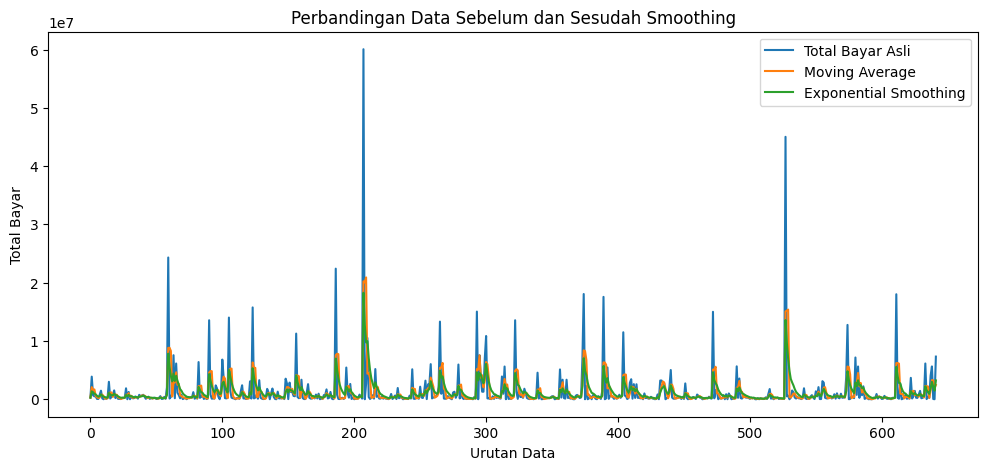

In [179]:
plt.figure(figsize=(12, 5))

plt.plot(
    data_smoothing["total_bayar"].reset_index(drop=True),
    label="Total Bayar Asli"
)
plt.plot(
    data_smoothing["Total_Bayar_MA"].reset_index(drop=True),
    label="Moving Average"
)
plt.plot(
    data_smoothing["Total_Bayar_ES"].reset_index(drop=True),
    label="Exponential Smoothing"
)

plt.xlabel("Urutan Data")
plt.ylabel("Total Bayar")
plt.title("Perbandingan Data Sebelum dan Sesudah Smoothing")
plt.legend()
plt.show()


**10. Grafik Perbandingan Sebelum dan Sesudah Transformasi**

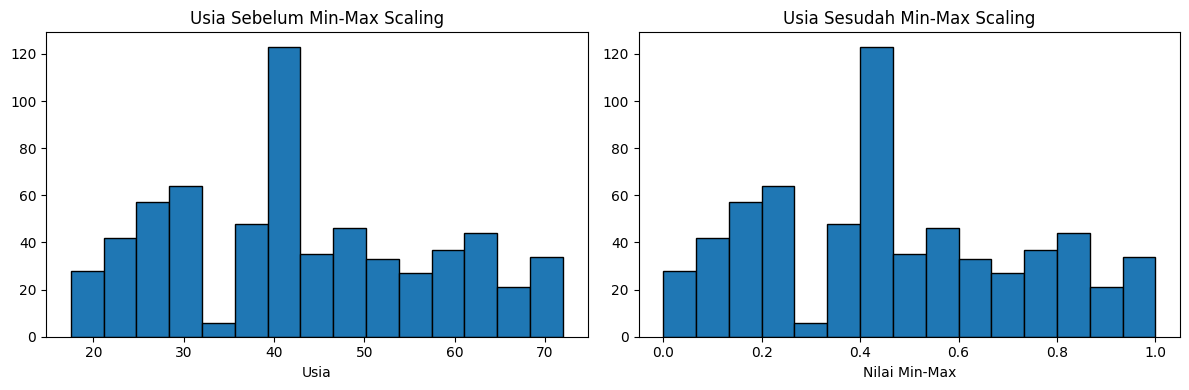

In [180]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(data["usia_pelanggan"].dropna(), bins=15, edgecolor="black")
ax[0].set_title("Usia Sebelum Min-Max Scaling")
ax[0].set_xlabel("Usia")

ax[1].hist(data_minmax["usia_pelanggan"], bins=15, edgecolor="black")
ax[1].set_title("Usia Sesudah Min-Max Scaling")
ax[1].set_xlabel("Nilai Min-Max")

plt.tight_layout()
plt.show()
